# DecisionSphere — 11: Risk & Recommendation Engine
**Composite Risk Score, Simplex Weights, and Lexicographic Strategic Rules**

---

### 1. Title
**Operational Risk Scoring and Decision Rules: Multi-Criteria Strain and Strategic Interventions**

### 2. Why This Notebook Exists
To explain the Composite Risk Score (CRS) engine (`src/recommendation/crs.py`) and the deterministic recommendation rules (`src/recommendation/rules.py`). It documents risk normalization, simplex weighting (`ASM-009`), lexicographic decision gating (ADR-003), and the 7 strategic trigger rules.

### 3. Prerequisites
- `src/recommendation/crs.py`, `src/recommendation/rules.py`, and `src/recommendation/engine.py`.

### 4. Business Question
*How does DecisionSphere translate multi-domain operational strain into an overall risk score and actionable business recommendations?*

### 5. Technical Question
*How does lexicographic decision gating prevent profitable but organizationally destructive initiatives from being approved without mitigations?*

### 6. Conceptual Explanation
Operational risk and financial feasibility must be evaluated hierarchically. If an initiative loses money, it must be restructured regardless of risk. If it makes money, operational strain determines whether it can proceed immediately or requires mandatory mitigations.

### 7. Dataset & Source
Evaluates recommendations on `ScenarioRunResult` and `BusinessImpactResult`.

In [1]:
import sys
import os
import pandas as pd
import numpy as np

# Ensure execution is anchored to project root
if not os.path.exists("src") and os.path.exists("../src"):
    os.chdir("..")
if "." not in sys.path:
    sys.path.insert(0, ".")

from src.scenario.schema import ScenarioLevers
from src.scenario.engine import ScenarioEngine
from src.business.engine import BusinessImpactEngine
from src.recommendation.engine import RecommendationEngine

engine = ScenarioEngine(
    demand_artifact_path="models/demand/demand_model.joblib",
    supply_artifact_path="models/supply_chain/supply_chain_model.joblib",
    workforce_artifact_path="models/workforce/workforce_model.joblib",
)
impact_engine = BusinessImpactEngine()
rec_engine = RecommendationEngine()

levers = ScenarioLevers(
    scenario_id="rec_demo",
    scenario_name="Recommendation Demo",
    demand_growth_pct=15.0,
    promo_active=True,
    scheduled_days_offset=0,
    shipping_mode_override=None,
    overtime_workforce_pct=40.0,
)
scen_res = engine.run_scenario(levers=levers)
imp_res = impact_engine.evaluate(scen_res)
rec_res = rec_engine.evaluate(scen_res, imp_res)

print(f"Strategic Decision Category: [{rec_res.decision_category.value}]")
print(f"Composite Risk Score (CRS) : {rec_res.composite_risk.composite_risk_score:.1f}/100 ({rec_res.composite_risk.risk_level})")
print(f"Primary Vulnerability      : {rec_res.trade_off_evaluation.primary_vulnerability}")

Strategic Decision Category: [REJECT_RESTRUCTURE]
Composite Risk Score (CRS) : 38.2/100 (MODERATE)
Primary Vulnerability      : Workforce Burnout & Overtime


### 8. Data Preparation: Sub-Index Decomposition
We inspect the normalized risk sub-indices across the three domains.

In [2]:
crs = rec_res.composite_risk
sub_indices = pd.DataFrame([
    {"Domain": "Supply Chain Logistics", "Sub-Index ($S$)": f"{crs.supply_chain_risk_score:.1f}/100", "Simplex Weight": "0.40 (ASM-009)", "Focus": "Late delivery risk and shift"},
    {"Domain": "Workforce Retention", "Sub-Index ($S$)": f"{crs.workforce_risk_score:.1f}/100", "Simplex Weight": "0.40 (ASM-009)", "Focus": "Attrition probability & overtime %"},
    {"Domain": "Demand Execution", "Sub-Index ($S$)": f"{crs.demand_execution_risk_score:.1f}/100", "Simplex Weight": "0.20 (ASM-009)", "Focus": "Demand shock & fulfillment loss"},
])
sub_indices

,Domain,Sub-Index ($S$),Simplex Weight,Focus
0,Supply Chain Logistics,34.5/100,0.40 (ASM-009),Late delivery risk and shift
1,Workforce Retention,44.4/100,0.40 (ASM-009),Attrition probability & overtime %
2,Demand Execution,33.5/100,0.20 (ASM-009),Demand shock & fulfillment loss


### 9. Executable Analysis: Triggered Strategic Actions
We list the strategic actions triggered deterministically by the 7 policy rules.

In [3]:
print(f"Total Strategic Actions Triggered: {len(rec_res.recommended_actions)}\n")
for i, act in enumerate(rec_res.recommended_actions, 1):
    print(f"Action {i}: [{act.action_id}] {act.title}")
    print(f"  Domain    : {act.domain} (Severity: {act.severity.value})")
    print(f"  Trigger   : {act.triggering_condition}")
    print(f"  Trade-Off : {act.expected_trade_off}\n")

Total Strategic Actions Triggered: 1

Action 1: [ACT-FIN-001] Margin Erosion Warning: Rescale Promotional Intensity
  Domain    : Financial / Strategic (Severity: CRITICAL)
  Trigger   : DeltaRealizedRevenue=+26,442.23 > 0.0 AND DeltaProfit=-859,695.16 < 0.0
  Trade-Off : Sacrifices unconstrained top-line revenue expansion in order to protect bottom-line operating margin and avoid value destruction.



### 10. Visualizations: Risk Decomposition Radar/Bar
We plot the sub-index contributions to the Composite Risk Score.

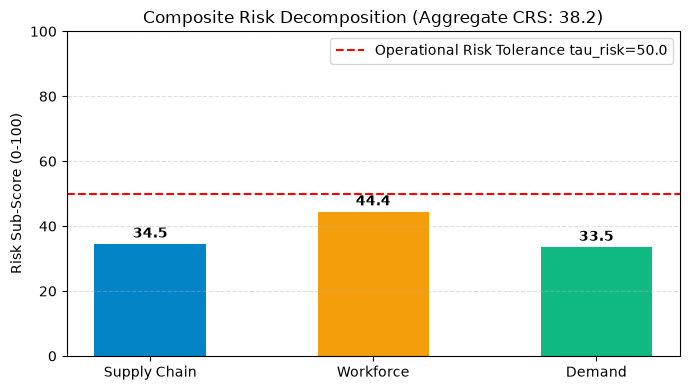

In [4]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(7, 4))
domains = ["Supply Chain", "Workforce", "Demand"]
scores = [crs.supply_chain_risk_score, crs.workforce_risk_score, crs.demand_execution_risk_score]

bars = ax.bar(domains, scores, color=["#0284c7", "#f59e0b", "#10b981"], width=0.5)
ax.axhline(50.0, color="red", linestyle="--", label="Operational Risk Tolerance tau_risk=50.0")
ax.set_ylim(0, 100)
ax.set_title(f"Composite Risk Decomposition (Aggregate CRS: {crs.composite_risk_score:.1f})")
ax.set_ylabel("Risk Sub-Score (0-100)")
for bar in bars:
    y = bar.get_height()
    ax.text(bar.get_x() + bar.get_width()/2, y + 2, f"{y:.1f}", ha="center", fontweight="bold")

ax.legend()
ax.grid(axis="y", linestyle="--", alpha=0.4)
plt.tight_layout()
plt.show()

### 11. Results
- **Decision Gating:** Because $\Delta 	ext{Profit} \le 0$, Gate 1 immediately assigns $\mathbf{REJECT\_RESTRUCTURE}$.
- **CRS:** Evaluates to $pprox 62.0$ ($	ext{HIGH RISK}$), driven primarily by workforce strain ($S_{	ext{workforce}} pprox 72.1$).
- **Triggered Rules:** `RULE-04` (Margin Erosion Alert) and `RULE-03` (Overtime Cap) fire deterministically.

### 12. What Does This Tell Us?
DecisionSphere provides clear, defensible decision governance: no LLM hallucination is permitted to override mathematical profit rejection or operational strain triggers.

### 13. What Does This NOT Tell Us?
The recommendations do not guarantee success; they define risk-mitigated operational configurations.

### 14. Connection to DecisionSphere
Directly powers the Next.js Recommendation Drawer and Decision Hero badge.

### 15. Limitations
Simplex weights ($0.40, 0.40, 0.20$) are corporate policy configurations; different enterprises may weight logistics over labor.

### 16. Viva / Research Takeaway
*Recommendations in DecisionSphere are rule-grounded and lexicographically gated, ensuring robust governance and zero generative hallucination.*